# Pizzeria Amalfi: liquidity forecast with XGBoost, MLflow and the CFO agent

This notebook is the *data science* half of the Autonomous CFO. It runs in a **Jupyter workbench on Red Hat OpenShift AI (RHOAI)**
inside our Data Science Project and covers the full loop:

1. look at the bank history (daily cash flow 2025, the **June shutdown**),
2. build calendar features and train an **XGBoost** regressor on the daily net cash flow,
3. evaluate it on a 60-day **holdout** against a **naive baseline**,
4. explain it (**feature importance and SHAP** for June 2026),
5. forecast the 2026 balance together with the **safety buffer** line,
6. play the **what-if**: a 30,000 EUR oven in March, the forecast crosses the buffer in summer and the agent drafts a **credit line proposal**,
7. log and register everything in **MLflow** (params, metrics, plots, model, alias `champion`) when `MLFLOW_TRACKING_URI` is set.

The notebook stays thin on purpose: all logic lives in the library `cfo.forecast` (`features`, `model`, `liquidity`), which the API and the agent
use as well. What you train here is what the agent explains to the CEO. The LLM never computes a number; it only phrases the result.

### Setup on an RHOAI workbench

1. Create a workbench in the Data Science Project (any recent *Standard Data Science* / Python 3.12 image works) and clone the repository
   into it (Git icon in the JupyterLab sidebar, or `git clone <repo-url> house` in a terminal).
2. Run this notebook with the repository root (the folder that contains `backend/`) as working directory, or set `REPO_DIR` below.
3. Install the library from the cloned repo (first code cell below; once per workbench, then restart the kernel):
   `pip install -e backend` (plus `matplotlib`, and `mlflow` if the workbench image does not have it).
4. Data source, in this order:
   * `DATABASE_URL`: the company Postgres, e.g. `postgresql://cfo:<password>@postgres:5432/cfo` in the cluster (default `localhost:5433` for local work).
   * fallback `SOURCE_CSV`: path or URL of the bank statement. In the cluster the CSV is served by the `files` service:
     `http://files:8080/pizzeria-amalfi-bank-statement-2025-v6.csv` (used automatically when nothing else is found).
   * Set variables in the workbench (*Edit workbench, Environment variables*) or in the first code cell with `os.environ[...] = ...`.
5. Optional: `MLFLOW_TRACKING_URI` switches MLflow logging on (explained in section 9).

In [1]:
# Run once per workbench, then restart the kernel. Uncomment the lines you need.
# %pip install -e backend            # the cfo library (pandas, xgboost, scikit-learn, psycopg ...) from the cloned repo
# %pip install matplotlib mlflow     # only if the workbench image does not ship them

import os

# Where the cloned repo lives (needed only if the kernel does not start inside it).
# os.chdir(os.path.expanduser("~/house"))

# Data source configuration (all optional, see the notes above):
# os.environ["DATABASE_URL"] = "postgresql://cfo:<password>@postgres:5432/cfo"
# os.environ["SOURCE_CSV"] = "http://files:8080/pizzeria-amalfi-bank-statement-2025-v6.csv"
# os.environ["MLFLOW_TRACKING_URI"] = "http://mlflow:5000"

## 1. Imports and configuration

In [2]:
import inspect
import tempfile
import textwrap
import urllib.request
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import psycopg
from xgboost import XGBRegressor

from cfo.config import get_settings
from cfo.data.source import CSV_NAME, SourceNotFound, find_source_csv, load_bank_csv
from cfo.forecast import features as feat
from cfo.forecast import liquidity
from cfo.forecast import model as fm

# One small, colour-blind-safe palette used by every chart.
BLUE, ORANGE, GREY, RED, GREEN = "#1f6fb2", "#d9730d", "#7a7a7a", "#c0392b", "#2e8b57"
plt.rcParams.update({
    "figure.dpi": 100, "figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold", "legend.frameon": False,
})
pd.options.display.float_format = "{:,.0f}".format

# The company database holds the history up to the end of November 2025 (December arrives live in the demo).
# The CSV fallback is cut at the same day, so both sources give the same training data.
HISTORY_END = pd.Timestamp("2025-11-30")
FIGURES = {}  # name -> matplotlib figure, also logged to MLflow in section 8


def eur(value):
    return f"{value:,.0f} EUR"

## 2. Load the transactions

The notebook first tries the company Postgres (`DATABASE_URL`). If it is not reachable or empty it falls back to the bank statement CSV
(`SOURCE_CSV`, a local file, a URL, or the in-cluster `files` service). Only aggregates are shown below, never raw statement rows.

In [3]:
def load_transactions() -> tuple[pd.DataFrame, str]:
    # 1) company database
    url = get_settings().database_url
    try:
        with psycopg.connect(url, connect_timeout=5) as conn:
            tx = feat.fetch_transactions(conn)
        if len(tx):
            return tx[tx["booking_date"] <= HISTORY_END].reset_index(drop=True), "postgres"
        print("Postgres is reachable but has no transactions, falling back to the CSV")
    except Exception as exc:  # noqa: BLE001 - any connection problem means: use the CSV
        print(f"Postgres not available ({type(exc).__name__}), falling back to the CSV")
    # 2) bank statement CSV: SOURCE_CSV (path or URL), the repo's usual places, or the in-cluster file server
    location = os.environ.get("SOURCE_CSV")
    if not location:
        try:
            location = str(find_source_csv())
        except SourceNotFound:
            location = f"http://files:8080/{CSV_NAME}"
    if location.startswith(("http://", "https://")):
        path = Path(tempfile.mkdtemp()) / CSV_NAME
        urllib.request.urlretrieve(location, path)
    else:
        path = Path(location)
    rows = [{"booking_date": t.booking_date, "amount": float(t.amount), "category": t.category,
             "team_id": t.team_id, "counterparty": t.counterparty, "invoice_id": None}
            for t in load_bank_csv(path)]
    tx = pd.DataFrame(rows)
    tx["booking_date"] = pd.to_datetime(tx["booking_date"])
    return tx[tx["booking_date"] <= HISTORY_END].reset_index(drop=True), "csv"


tx, source = load_transactions()
print(f"source: {source}")
print(f"{len(tx)} bookings from {tx['booking_date'].min().date()} to {tx['booking_date'].max().date()}")
print(f"balance at the end of the history (sum of all bookings): {eur(tx['amount'].sum())}")

Postgres not available (UndefinedTable), falling back to the CSV
source: csv
1022 bookings from 2025-01-01 to 2025-11-30
balance at the end of the history (sum of all bookings): 23,552 EUR


## 3. Data overview: daily cash flow 2025 and the June shutdown

`daily_cash_flow` turns the bookings into one row per calendar day (quiet days are 0). The statement has no opening balance,
so the balance is the running sum of the bookings (the organizer's own liquidity chart also starts at 0).

In [4]:
daily = feat.daily_cash_flow(tx, start=tx["booking_date"].min(), end=HISTORY_END)
daily["balance"] = daily["net_cash_flow"].cumsum()
monthly = daily.resample("MS")[["inflow", "outflow", "revenue", "net_cash_flow"]].sum()
monthly.index = monthly.index.strftime("%Y-%m")
print("Monthly totals (EUR):")
display(monthly.rename(columns={"net_cash_flow": "net"}))

Monthly totals (EUR):


,inflow,outflow,revenue,net
date,,,,
2025-01,"45,760","-45,038","45,760",722
2025-02,"42,011","-43,106","42,011","-1,094"
2025-03,"45,720","-45,989","45,720",-269
2025-04,"43,718","-42,510","43,718","1,208"
2025-05,"45,540","-45,713","45,540",-173
2025-06,0,"-21,897",0,"-21,897"
2025-07,"52,551","-43,588","52,551","8,963"
2025-08,"55,017","-45,279","55,017","9,738"
2025-09,"55,499","-45,021","55,499","10,478"


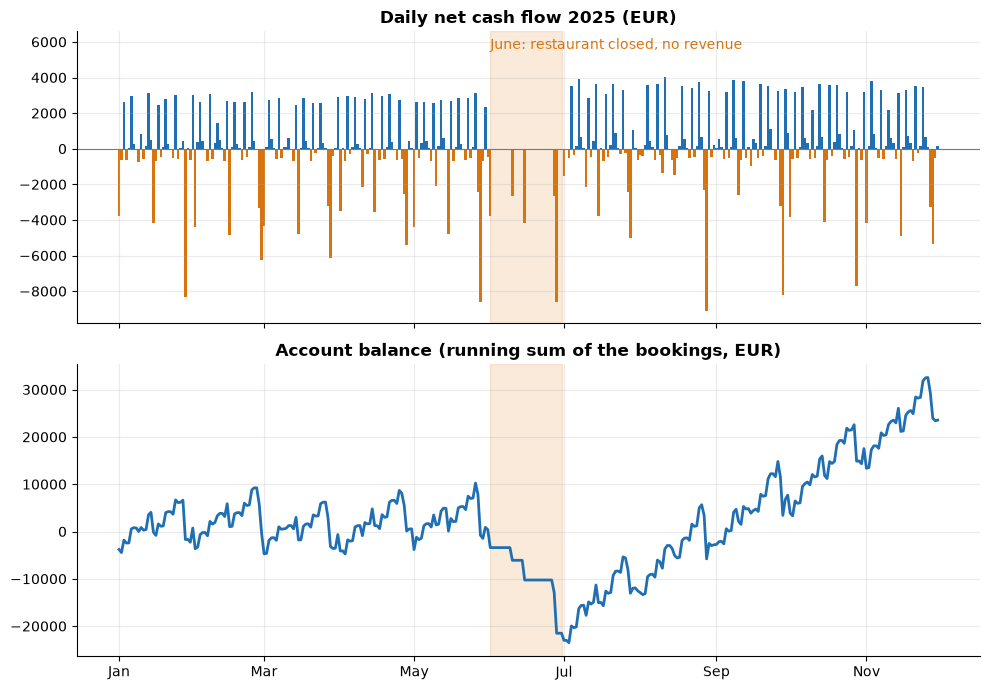

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
ax1.bar(daily.index, daily["net_cash_flow"], color=np.where(daily["net_cash_flow"] >= 0, BLUE, ORANGE), width=1.0)
ax1.set_title("Daily net cash flow 2025 (EUR)")
ax1.axhline(0, color=GREY, lw=0.8)
ax2.plot(daily.index, daily["balance"], color=BLUE, lw=2)
ax2.set_title("Account balance (running sum of the bookings, EUR)")
june = (pd.Timestamp("2025-06-01"), pd.Timestamp("2025-06-30"))
for ax in (ax1, ax2):
    ax.axvspan(*june, color=ORANGE, alpha=0.15)
ax1.set_ylim(top=ax1.get_ylim()[1] * 1.4)
ax1.annotate("June: restaurant closed, no revenue", (june[0], ax1.get_ylim()[1] * 0.85), color=ORANGE, fontsize=10)
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.tight_layout()
FIGURES["01_daily_cash_flow"] = fig
plt.show()

Inferred shutdown: 30 days, from (month, day) (6, 1) to (6, 30)


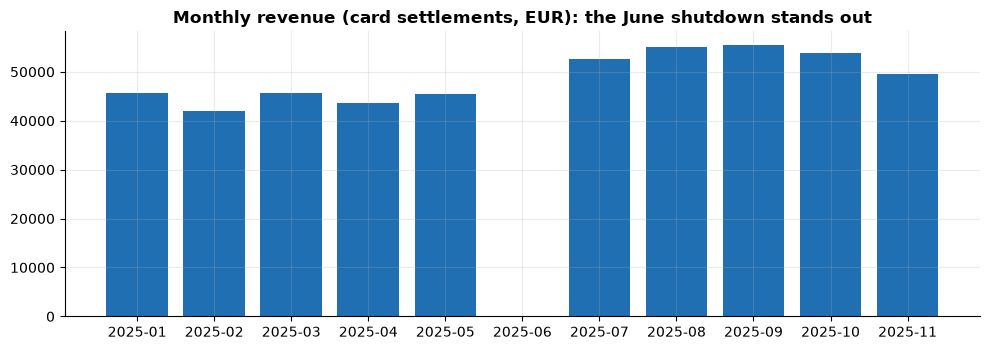

In [6]:
shutdown = sorted(feat.infer_shutdown_days(tx))
print(f"Inferred shutdown: {len(shutdown)} days, from (month, day) {shutdown[0]} to {shutdown[-1]}")
fig, ax = plt.subplots(figsize=(10, 3.6))
colors = [ORANGE if m == 6 else BLUE for m in range(1, len(monthly) + 1)]
ax.bar(monthly.index, monthly["revenue"], color=colors)
ax.set_title("Monthly revenue (card settlements, EUR): the June shutdown stands out")
fig.tight_layout()
FIGURES["02_monthly_revenue"] = fig
plt.show()

**What we see.** Revenue is steady all year except June, when the pizzeria is closed: no card settlements at all, yet payroll, rent,
taxes and social security keep running. The net cash flow of June is clearly negative and the balance drops. A model that knows the calendar
should reproduce this dip in June 2026. Whether the dip is dangerous depends on the cash cushion at that moment; that is what the rest of the notebook tests.

## 4. Features and training

`daily_features` adds calendar features to every day, also for future days: weekday, month, quarter, day of year, month start/end,
German public holidays, **`shutdown_flag`** (the days of the yearly closure, inferred from the history) and flags for the days on which
payroll, rent, tax, social security and utilities are normally booked (also inferred from the history).

Target: daily net cash flow **without** the 12 Swiss partner tranches. That schedule ends on 15 December 2025, so it is not a behaviour to
learn; it is added back as a known scheduled payment in the forecast.

In [7]:
features = feat.daily_features(tx, end=HISTORY_END, exclude_categories=fm.EXCLUDED_CATEGORIES)
print(f"{len(feat.CALENDAR_COLUMNS)} features:", ", ".join(feat.CALENDAR_COLUMNS))
print(f"{features['net_cash_flow'].notna().sum()} training days")

17 features: weekday, is_weekend, month, quarter, day_of_month, day_of_year, week_of_year, days_to_month_end, is_month_start, is_month_end, is_public_holiday, shutdown_flag, payroll_due, rent_due, tax_due, social_security_due, utilities_due
334 training days


### Train the XGBoost model

200 shallow trees (depth 3), fixed seed, so every run is reproducible. `train` fits on all days and also runs a time-based backtest
(fit on everything but the last 60 days, score on those 60). With one year of history a cross-validation by year is impossible (the shutdown
happens once), so a holdout of ordinary days is the honest check. MLflow logging is done explicitly in section 8, therefore `log_to_mlflow=False` here.

In [8]:
model = fm.train(tx, log_to_mlflow=False)
print("hyperparameters:", {k: model.params[k] for k in ("n_estimators", "max_depth", "learning_rate", "min_child_weight")})
print("trained until:", model.trained_until.date())
print("inferred shutdown days:", len(model.shutdown_days), "| due days:", model.due_days)

hyperparameters: {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.05, 'min_child_weight': 3}
trained until: 2025-11-30
inferred shutdown days: 30 | due days: {'payroll': (28,), 'rent': (1,), 'tax': (10, 15), 'social_security': (27,), 'utilities': (10,)}


## 5. Holdout evaluation against the naive baseline

The **naive baseline** predicts the average daily net cash flow of the training period for every day. The model must beat it clearly,
otherwise the calendar features would add nothing.

In [9]:
HOLDOUT = int(model.metrics["holdout_days"])
table = feat.daily_features(tx, end=HISTORY_END, exclude_categories=fm.EXCLUDED_CATEGORIES).dropna(subset=["net_cash_flow"])
train_part, test_part = table.iloc[:-HOLDOUT], table.iloc[-HOLDOUT:]
holdout_model = XGBRegressor(**model.params).fit(train_part[fm.FEATURE_COLUMNS], train_part["net_cash_flow"])
pred = pd.Series(holdout_model.predict(test_part[fm.FEATURE_COLUMNS]), index=test_part.index)
naive = pd.Series(train_part["net_cash_flow"].mean(), index=test_part.index)

mae_model = float(np.abs(pred - test_part["net_cash_flow"]).mean())
mae_naive = float(np.abs(naive - test_part["net_cash_flow"]).mean())
assert abs(mae_model - model.metrics["holdout_mae"]) < 1e-6  # same numbers as stored in model.metrics (and logged to MLflow)
results = pd.DataFrame({"MAE (EUR/day)": [mae_model, mae_naive],
                        "RMSE (EUR/day)": [model.metrics["holdout_rmse"],
                                           float(np.sqrt(((naive - test_part["net_cash_flow"]) ** 2).mean()))]},
                       index=["XGBoost", "naive mean"])
display(results)
print(f"The model's daily error is {mae_naive / mae_model:.1f}x smaller than the baseline's "
      f"(holdout: {test_part.index.min().date()} to {test_part.index.max().date()}).")

,MAE (EUR/day),RMSE (EUR/day)
XGBoost,207,307
naive mean,"1,415","2,161"


The model's daily error is 6.9x smaller than the baseline's (holdout: 2025-10-02 to 2025-11-30).


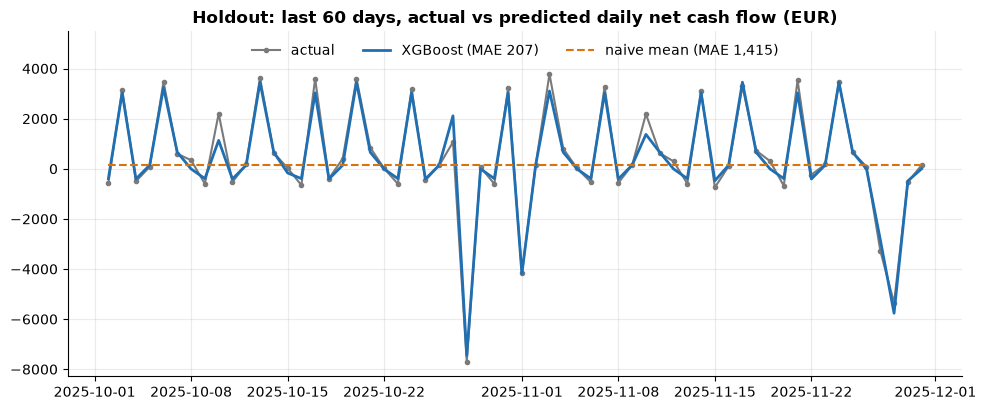

In [10]:
fig, ax = plt.subplots()
ax.plot(test_part.index, test_part["net_cash_flow"], color=GREY, lw=1.5, marker="o", ms=3, label="actual")
ax.plot(pred.index, pred, color=BLUE, lw=2, label=f"XGBoost (MAE {mae_model:,.0f})")
ax.plot(naive.index, naive, color=ORANGE, lw=1.5, ls="--", label=f"naive mean (MAE {mae_naive:,.0f})")
ax.set_title(f"Holdout: last {HOLDOUT} days, actual vs predicted daily net cash flow (EUR)")
ax.set_ylim(top=test_part["net_cash_flow"].max() * 1.45)
ax.legend(ncol=3, loc="upper center")
fig.tight_layout()
FIGURES["03_holdout_actual_vs_predicted"] = fig
plt.show()

The model follows the spikes (payroll, rent, tax days) that the flat baseline cannot see. Remaining errors are single days whose size depends on
unpredictable card revenue, which is acceptable for a monthly liquidity view.

## 6. Explainability: feature importance and SHAP

* **Feature importance** (share of total gain) shows which features the trees use at all.
* **SHAP contributions** split each daily prediction into per-feature euro amounts (they sum to the prediction). Summed over June 2026 they answer:
  *why does the model expect a bad June?* This is exactly the evidence the agent hands to the LLM to explain the forecast in plain language.

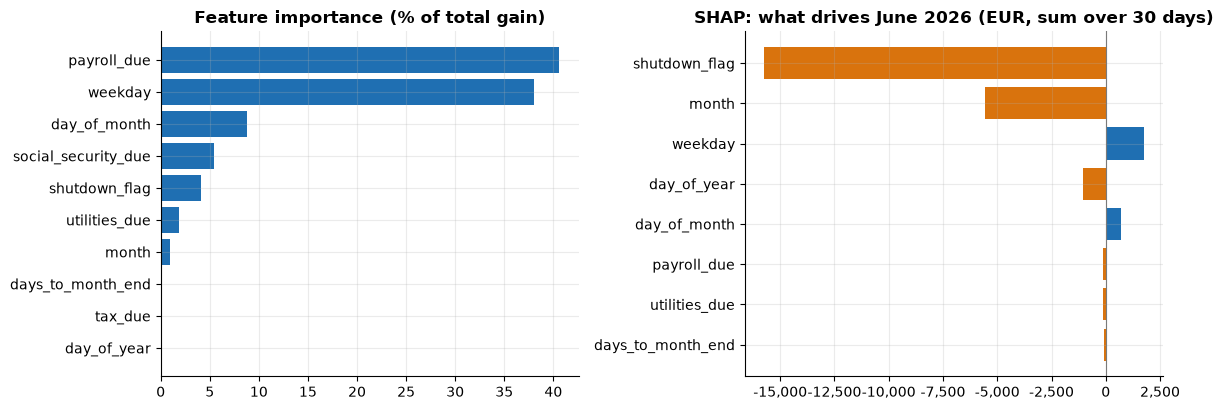

Predicted net cash flow June 2026: -14,113 EUR (model baseline for 30 days: 6,270 EUR)


In [11]:
importances = model.feature_importances().head(10)[::-1]
june_2026 = ("2026-06-01", "2026-06-30")
explain = model.explain(*june_2026, top=8)
drivers = pd.Series({d["feature"]: d["contribution_eur"] for d in explain["top_drivers"]})[::-1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.barh(importances.index, importances.values * 100, color=BLUE)
ax1.set_title("Feature importance (% of total gain)")
ax2.barh(drivers.index, drivers.values, color=np.where(drivers.values >= 0, BLUE, ORANGE))
ax2.axvline(0, color=GREY, lw=0.8)
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax2.set_title(f"SHAP: what drives June 2026 (EUR, sum over {explain['days']} days)")
fig.tight_layout()
FIGURES["04_importance_and_shap"] = fig
plt.show()

print(f"Predicted net cash flow June 2026: {eur(explain['predicted_net_eur'])} "
      f"(model baseline for 30 days: {eur(explain['baseline_eur'])})")

By gain, the trees rely mostly on `payroll_due` and `weekday`: they explain the daily rhythm (payroll, rent and tax days, weekend revenue). The *June*
prediction is a different question, and SHAP answers it: `shutdown_flag` and `month` contribute large negative amounts, while the weekday pattern is slightly positive. The model did not simply memorize a number: the dip is attributed to the *closure*, which the agent can name.

## 7. The 2026 liquidity forecast with the safety buffer

`forecast_with` walks the predicted daily net cash flow forward from the last known balance (plus the known schedule of the remaining partner tranche)
for 240 days, up to the end of July 2026.

Per decision D-013, a **liquidity gap** is not "balance below zero" but **balance below the safety buffer**: one month of fixed costs
(payroll, rent, tax, social security, utilities; the most expensive month of the history). Crossing it is the point where a CFO should act.

In [12]:
base = liquidity.forecast_with(model=model, transactions=tx)
buffer = float(liquidity.default_buffer(tx))
summer = base.loc["2026-06-01":"2026-07-10"]  # the June shutdown and the payroll/rent days that follow it
day, low = fm.lowest_balance(summer)
gaps = liquidity.detect_gaps(base, buffer)

monthly_fc = base["net"].resample("MS").sum()
monthly_fc.index = monthly_fc.index.strftime("%Y-%m")
print(f"safety buffer (one month of fixed costs): {eur(buffer)}")
print(f"start balance {eur(base.attrs['start_balance'])} on {base.attrs['last_known_date']}")
print(f"lowest predicted balance around the June shutdown: {eur(low)} on {day.date()}")
print(f"gaps below the buffer in the base case: {len(gaps)}")
print("\nPredicted net cash flow per month (EUR):")
display(monthly_fc.to_frame("net"))

safety buffer (one month of fixed costs): 17,730 EUR
start balance 23,552 EUR on 2025-11-30
lowest predicted balance around the June shutdown: 42,527 EUR on 2026-07-02
gaps below the buffer in the base case: 0

Predicted net cash flow per month (EUR):


,net
date,
2025-12,"11,057"
2026-01,"5,223"
2026-02,"3,780"
2026-03,"6,331"
2026-04,"4,268"
2026-05,"5,814"
2026-06,"-14,113"
2026-07,"12,149"


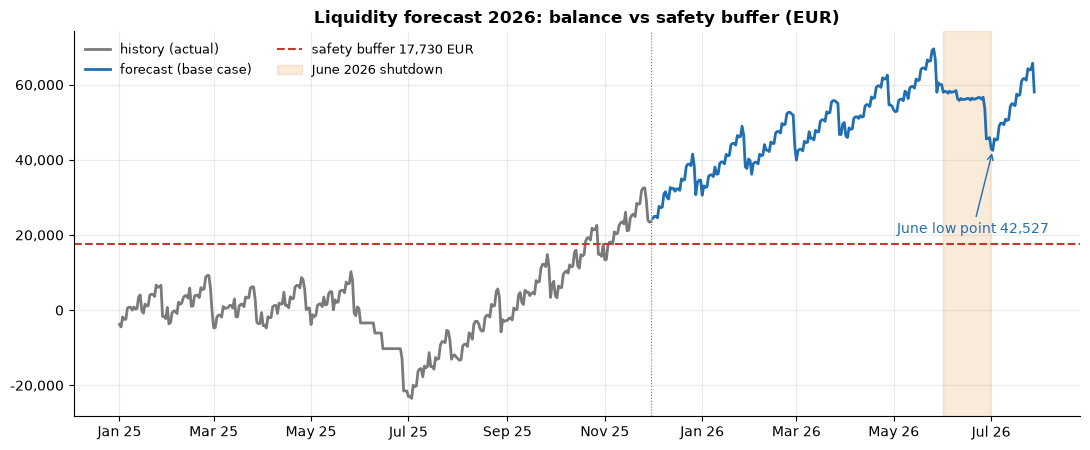

In [13]:
def balance_chart(ax, forecasts, title):
    hist = daily["balance"]
    ax.plot(hist.index, hist, color=GREY, lw=2, label="history (actual)")
    for label, fc, color, style in forecasts:
        ax.plot(fc.index, fc["balance"], color=color, lw=2, ls=style, label=label)
    ax.axhline(buffer, color=RED, lw=1.5, ls="--", label=f"safety buffer {buffer:,.0f} EUR")
    ax.axvspan(pd.Timestamp("2026-06-01"), pd.Timestamp("2026-06-30"), color=ORANGE, alpha=0.15, label="June 2026 shutdown")
    ax.axvline(pd.Timestamp(base.attrs["last_known_date"]), color=GREY, lw=0.8, ls=":")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
    ax.set_title(title)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.legend(loc="upper left", ncol=2, fontsize=9)


fig, ax = plt.subplots(figsize=(11, 4.6))
balance_chart(ax, [("forecast (base case)", base, BLUE, "-")], "Liquidity forecast 2026: balance vs safety buffer (EUR)")
low_x, low_y = day, low
ax.annotate(f"June low point {low_y:,.0f}", (low_x, low_y), xytext=(low_x - pd.Timedelta(days=60), low_y - 22000), color=BLUE,
            arrowprops={"arrowstyle": "->", "color": BLUE})
fig.tight_layout()
FIGURES["05_forecast_with_buffer"] = fig
plt.show()

**Reading the chart.** The cushion from a good winter and spring (the tranche schedule also ends) is large enough that the June dip stays **above** the buffer in the
base case, so there is **no gap and no credit is needed**. The agent still sees something useful: a weak month is coming while cash is idle,
so it proposes parking part of the surplus (an investment proposal, sized so that the balance stays at or above the buffer afterwards).

In [14]:
review_base = liquidity.review_liquidity(model=model, transactions=tx)
for p in review_base.proposals:
    print(f"Proposal: {p.action_type}, {eur(p.amount)} ({p.instrument}), from {p.period_start} to {p.period_end}; "
          f"policy level: {p.level.value}")
    print(textwrap.fill(p.reason, 120))
if not review_base.proposals:
    print("No proposal in the base case.")

Proposal: make_investment, 24,500 EUR (money market fund), from 2026-05-26 to 2026-06-30; policy level: APPROVAL
June 2026: the restaurant is closed about 4 weeks, so revenue drops by about 47,600 EUR against a normal month, while
fixed costs of 17,730 EUR per month continue. The model expects a net cash flow of -14,113 EUR in June 2026, mainly
because of the summer shutdown (-15,758 EUR); the usual seasonal pattern of the month (-5,586 EUR); the weekday pattern
(+1,766 EUR). From 2026-05-26 the balance stays above the safety buffer of 17,730 EUR (lowest 42,527 EUR on 2026-07-02),
so 24,500 EUR can earn interest in a money market fund and the balance still never falls below 18,027 EUR, 297 EUR above
the buffer.


## 8. What-if: a 30,000 EUR oven in March

The CEO asks the agent: *"What if I buy a new oven for 30,000 EUR in March?"* The extra outflow is added to the forecast and the same
gap detection runs again. The oven eats the cushion: the balance touches the buffer right after the purchase (a few small dips on payroll and rent days in March and April)
and the June shutdown then pushes it clearly **below the buffer**. The agent turns the
deepest shortfall into a **credit line proposal** (shortfall plus 20% reserve, rounded up to 1,000 EUR, from two weeks before the gap until a month after it
recovers). Taking out a credit line is always an **APPROVAL** action: the CEO decides, the agent only prepares the case.

In [15]:
oven = liquidity.Outflow(on=date(2026, 3, 15), amount=30_000, label="oven")
review = liquidity.review_liquidity([oven], model=model, transactions=tx)
what_if = review.forecast

print(f"Gaps below the buffer of {eur(float(review.buffer))}:")
gap_table = pd.DataFrame([{"from": g.start, "to": g.end, "lowest day": g.lowest_date,
                           "lowest balance": float(g.lowest_balance), "shortfall": float(g.shortfall),
                           "back above buffer": g.recovery_date} for g in review.gaps])
display(gap_table)

proposal = review.proposals[0]
print(f"\nProposal: {proposal.action_type}, {eur(proposal.amount)}, "
      f"from {proposal.period_start} to {proposal.period_end} (policy level: {proposal.level.value})")
print(textwrap.fill(proposal.reason, 120))

Gaps below the buffer of 17,730 EUR:


,from,to,lowest day,lowest balance,shortfall,back above buffer
0,2026-03-15,2026-03-15,2026-03-15,"17,465",265,2026-03-16
1,2026-03-28,2026-03-29,2026-03-28,"16,744",986,2026-03-30
2,2026-04-01,2026-04-02,2026-04-02,"15,944","1,786",2026-04-03
3,2026-06-28,2026-07-05,2026-07-02,"12,527","5,203",2026-07-06



Proposal: request_credit_line, 7,000 EUR, from 2026-03-01 to 2026-08-05 (policy level: APPROVAL)
June 2026: the restaurant is closed about 4 weeks, so revenue drops by about 47,600 EUR against a normal month, while
fixed costs of 17,730 EUR per month continue. Planned in this scenario: oven 30,000 EUR on 2026-03-15. The model expects
a net cash flow of -14,113 EUR in June 2026, mainly because of the summer shutdown (-15,758 EUR); the usual seasonal
pattern of the month (-5,586 EUR); the weekday pattern (+1,766 EUR). The balance is predicted to fall to 12,527 EUR on
2026-07-02, 5,203 EUR below the safety buffer of 17,730 EUR (one month of fixed costs). A credit line of 7,000 EUR from
2026-03-01 to 2026-08-05 covers the shortfall with a reserve.


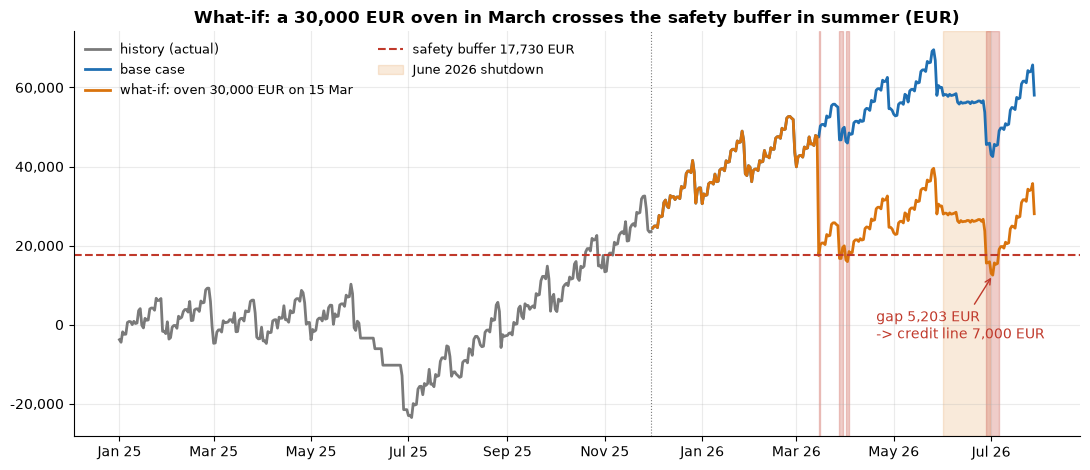

In [16]:
fig, ax = plt.subplots(figsize=(11, 4.8))
balance_chart(ax, [("base case", base, BLUE, "-"), ("what-if: oven 30,000 EUR on 15 Mar", what_if, ORANGE, "-")],
              "What-if: a 30,000 EUR oven in March crosses the safety buffer in summer (EUR)")
for g in review.gaps:
    ax.axvspan(pd.Timestamp(g.start), pd.Timestamp(g.end) + pd.Timedelta(days=1), color=RED, alpha=0.25)
worst = max(review.gaps, key=lambda g: g.shortfall)
ax.annotate(f"gap {float(worst.shortfall):,.0f} EUR\n-> credit line {float(proposal.amount):,.0f} EUR",
            (pd.Timestamp(worst.lowest_date), float(worst.lowest_balance)),
            xytext=(pd.Timestamp("2026-04-20"), float(worst.lowest_balance) - 16000), color=RED,
            arrowprops={"arrowstyle": "->", "color": RED})
fig.tight_layout()
FIGURES["06_what_if_oven"] = fig
plt.show()

The proposal text is **built in code from the forecast and the SHAP drivers**; amounts and dates never come from the LLM. In the running system this very
`LiquidityProposal` is sent to the agent graph, which asks the CEO in Slack and waits for *Approve* or *Reject*. Nothing is executed for real: banking actions are simulated.

## 9. MLflow: log and register the model

Everything above stays reproducible once it is tracked. When `MLFLOW_TRACKING_URI` is set, the cell below creates **one MLflow run** in the experiment
`liquidity-forecast` with:

* **params**: the XGBoost hyperparameters and the excluded categories,
* **metrics**: holdout MAE/RMSE, naive MAE, training error, number of training days,
* **model**: the XGBoost booster (plus the calendar metadata the API needs to rebuild the model), registered as `liquidity-forecast` with alias **`champion`**,
* **plots**: all figures from this notebook as run artifacts.

**How to switch it on in RHOAI.** Open your workbench, *Edit workbench, Environment variables* and add
`MLFLOW_TRACKING_URI=http://mlflow:5000` (the in-cluster service of the MLflow tracking server; use the Route URL if you work from outside the
cluster, and use the actual service name if it differs), then restart the workbench. Without the variable this section is a no-op, so the notebook also runs offline.
For a quick local try: `MLFLOW_TRACKING_URI=sqlite:///mlflow.db` (needs `pip install mlflow`).

In [17]:
tracking_uri = os.environ.get("MLFLOW_TRACKING_URI")
run_id = None
if not tracking_uri:
    print("MLFLOW_TRACKING_URI is not set: MLflow logging skipped.")
    print("On RHOAI: workbench -> Edit workbench -> Environment variables -> MLFLOW_TRACKING_URI=http://mlflow:5000")
else:
    import mlflow

    kwargs = {"register": True} if "register" in inspect.signature(fm.log_to_mlflow_if_configured).parameters else {}
    logged = fm.log_to_mlflow_if_configured(model, **kwargs)  # params, metrics, booster (+ registry alias `champion`)
    if isinstance(logged, str):
        run_id = logged
    elif logged:  # older library version returns True only: take the newest run of the experiment
        runs = mlflow.search_runs(experiment_names=[fm.MLFLOW_EXPERIMENT], max_results=1, order_by=["start_time DESC"])
        run_id = runs.loc[0, "run_id"] if len(runs) else None
    if run_id:
        with mlflow.start_run(run_id=run_id):  # add the notebook's plots and what-if result to the same run
            for name, fig in FIGURES.items():
                mlflow.log_figure(fig, f"plots/{name}.png")
            mlflow.log_metric("whatif_oven_credit_line_eur", float(proposal.amount))
            mlflow.log_metric("base_case_lowest_balance_eur", low)
        experiment_id = mlflow.get_run(run_id).info.experiment_id
        print(f"MLflow run: {tracking_uri.rstrip('/')}/#/experiments/{experiment_id}/runs/{run_id}")
        print("Registered model: liquidity-forecast, alias: champion" if kwargs else
              "Model logged (the registry alias needs the T026 version of cfo.forecast.model)")
    else:
        print("MLflow logging did not produce a run (see the warning above).")

MLFLOW_TRACKING_URI is not set: MLflow logging skipped.
On RHOAI: workbench -> Edit workbench -> Environment variables -> MLFLOW_TRACKING_URI=http://mlflow:5000


### How the API picks up the new version

The CFO API does not need a restart after retraining. It resolves the model from the MLflow registry through the setting `FORECAST_MODEL_URI`:

```
MLFLOW_TRACKING_URI=http://mlflow:5000
FORECAST_MODEL_URI=models:/liquidity-forecast@champion
```

Training in this notebook with `register=True` registers a new version and moves the alias `champion` to it. The API re-resolves the alias
at most every 60 seconds, loads the new booster plus calendar metadata, and then reports the new `mlflow_run_id` and version in `/v1/forecast/...`.
To roll back, point the alias `champion` at an older version in the MLflow UI. If MLflow is unreachable, the API falls back to the model file
`FORECAST_MODEL_PATH` (default `models/liquidity_xgb.json`) or trains on first use, so the demo never depends on the registry being up.

## Summary

| Question | Answer from this notebook |
|---|---|
| Does the data show a clear June problem? | Yes: no revenue in June 2025 while fixed costs continue. |
| Does the model beat a naive baseline? | Yes, holdout MAE is several times smaller (section 5). |
| Why does the model expect a bad June 2026? | The SHAP contribution of `shutdown_flag` and `month` (section 6). |
| Is the base case in danger? | No gap below the safety buffer; the agent proposes investing idle cash (section 7). |
| What if the CEO buys a 30,000 EUR oven in March? | The balance falls below the buffer after the June shutdown; the agent drafts a credit line proposal for CEO approval (section 8). |
| Where is it tracked? | MLflow experiment `liquidity-forecast`, model `liquidity-forecast@champion` (section 9). |